In [1]:
import os
import json
import numpy as np
import pandas as pd
import joblib
import xgboost as xgb
from datetime import datetime
from sqlalchemy import create_engine, text
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    recall_score, precision_score, f1_score,
    accuracy_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
import time
import catboost as cb
import matplotlib.pyplot as plt
import os
from pathlib import Path
from dotenv import load_dotenv

# Определяем корень проекта 
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent 
print(NOTEBOOK_DIR)
print(PROJECT_ROOT)

# Путь к .env
env_path = PROJECT_ROOT / ".env"
print(f"📁 Ищем файл .env по пути: {env_path}")

if not env_path.exists():
    raise FileNotFoundError(
        f"❌ Файл .env не найден!\n"
        f"Убедитесь, что он лежит в корне проекта: {PROJECT_ROOT}"
    )

# Загружаем переменные окружения
load_dotenv(env_path)

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

# Создаем engine
engine = create_engine(f"postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

# Тест подключения
with engine.connect() as conn:
    conn.execute(text("SELECT 1"))
    
print("\n✅ Подключение к PostgreSQL успешно установлено!")

# Настройка пути к моделям 
MODELS_DIR = PROJECT_ROOT / "models"
print(f"✅ Папка моделей: {MODELS_DIR}")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

MODEL_VERSION = "v2"


print(f"✅ Random seed: {RANDOM_SEED}")
print(f"✅ Модели: {MODELS_DIR}")

C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\notebooks
C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor
📁 Ищем файл .env по пути: C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\.env

✅ Подключение к PostgreSQL успешно установлено!
✅ Папка моделей: C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\models
✅ Random seed: 42
✅ Модели: C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\models


In [2]:
# --- Загрузка drug_features_2 ---
df = pd.read_sql(
    "SELECT * FROM synthetic_data.drug_features_2",
    engine,
)

print(f"✅ drug_features_2: {len(df):,} строк × {len(df.columns)} колонок")
print(f"\n📋 Колонки ({len(df.columns)}):")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col} ({df[col].dtype})")

# --- Проверка target ---
print(f"\n📊 deficit_risk:")
print(df['deficit_risk'].value_counts().sort_index())

✅ drug_features_2: 7,672 строк × 40 колонок

📋 Колонки (40):
   1. smnn_code (object)
   2. standard_inn (object)
   3. products_count (int64)
   4. producers_count (int64)
   5. trade_count (int64)
   6. form_count (int64)
   7. doze_count (int64)
   8. reg_num_count (int64)
   9. atc_group_mode (object)
  10. has_combined_atc (int64)
  11. is_essential (int64)
  12. is_narcotic (int64)
  13. country_group_mode (object)
  14. has_russian_producer (int64)
  15. countries_count (int64)
  16. primary_unit_type (object)
  17. primary_unit_name (object)
  18. avg_age (float64)
  19. min_age (float64)
  20. max_age (float64)
  21. log_products_count (float64)
  22. log_klp_code_count (float64)
  23. log_reg_num_count (float64)
  24. log_trade_count (float64)
  25. log_producers_count (float64)
  26. products_per_producer (float64)
  27. log_products_per_producer (float64)
  28. reg_num_per_producer (float64)
  29. trade_per_producer (float64)
  30. atc_is_unknown (int64)
  31. atc_substitut

In [3]:
# --- Удаляем служебные колонки ---
COLS_TO_DROP = [
    'id',              # автоинкремент
    'created_at',      # время создания
    'updated_at',      # время обновления
    'smnn_code',       # ID
    'standard_inn',    # ID
    'deficit_risk',    # target (пока уберём, потом вернём как y)
]

df_clean = df.drop(columns=[c for c in COLS_TO_DROP if c in df.columns])

print(f"✅ df_clean: {len(df_clean):,} строк × {len(df_clean.columns)} колонок")
print(f"📋 Признаки ({len(df_clean.columns)}):")
for i, col in enumerate(df_clean.columns, 1):
    print(f"  {i:2d}. {col} ({df_clean[col].dtype})")

# --- Проверка NaN ---
nan_count = df_clean.isnull().sum().sum()
print(f"\n📊 NaN в df_clean: {nan_count}")
assert nan_count == 0, "❌ Есть NaN!"

# --- Проверка типов (все числовые, кроме категориальных) ---
CATEGORICAL = ['atc_group_mode', 'country_group_mode', 'primary_unit_type', 'primary_unit_name']
for col in df_clean.columns:
    if col in CATEGORICAL:
        continue
    if not pd.api.types.is_numeric_dtype(df_clean[col]) and df_clean[col].dtype != bool:
        print(f"⚠️  {col}: dtype={df_clean[col].dtype} — не числовой!")

✅ df_clean: 7,672 строк × 37 колонок
📋 Признаки (37):
   1. products_count (int64)
   2. producers_count (int64)
   3. trade_count (int64)
   4. form_count (int64)
   5. doze_count (int64)
   6. reg_num_count (int64)
   7. atc_group_mode (object)
   8. has_combined_atc (int64)
   9. is_essential (int64)
  10. is_narcotic (int64)
  11. country_group_mode (object)
  12. has_russian_producer (int64)
  13. countries_count (int64)
  14. primary_unit_type (object)
  15. primary_unit_name (object)
  16. avg_age (float64)
  17. min_age (float64)
  18. max_age (float64)
  19. log_products_count (float64)
  20. log_klp_code_count (float64)
  21. log_reg_num_count (float64)
  22. log_trade_count (float64)
  23. log_producers_count (float64)
  24. products_per_producer (float64)
  25. log_products_per_producer (float64)
  26. reg_num_per_producer (float64)
  27. trade_per_producer (float64)
  28. atc_is_unknown (int64)
  29. atc_substitutes_count (int64)
  30. has_atc_substitutes (int64)
  31. log

In [4]:
# --- X и y ---
X = df_clean.copy()
y = df['deficit_risk'].copy()

print(f"✅ X: {X.shape}")
print(f"✅ y: {y.shape}")
print(f"\n📊 Распределение y:\n{y.value_counts(normalize=True).round(3)}")

# --- Шаг 1: train (80%) vs temp (20%) ---
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_SEED,
)

# --- Шаг 2: temp (20%) → val (10%) + test (10%) ---
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_SEED,
)

print(f"\n{'='*60}")
print("SPLIT")
print(f"{'='*60}")
print(f"  TRAIN: {len(X_train):,} ({len(X_train)/len(X)*100:.1f}%)")
print(f"  VAL:   {len(X_val):,} ({len(X_val)/len(X)*100:.1f}%)")
print(f"  TEST:  {len(X_test):,} ({len(X_test)/len(X)*100:.1f}%)")
print(f"  Всего: {len(X):,}")

print(f"\n📊 Распределение классов по сплитам:")
print(f"  {'Класс':<8} {'TRAIN':<20} {'VAL':<20} {'TEST':<20}")
print(f"  {'-'*68}")
for cls in sorted(y.unique()):
    tr = (y_train == cls).sum()
    va = (y_val == cls).sum()
    te = (y_test == cls).sum()
    tr_pct = tr / len(y_train) * 100
    va_pct = va / len(y_val) * 100
    te_pct = te / len(y_test) * 100
    print(f"  {cls:<8} {tr:>5} ({tr_pct:>4.1f}%)   {va:>5} ({va_pct:>4.1f}%)   {te:>5} ({te_pct:>4.1f}%)")

✅ X: (7672, 37)
✅ y: (7672,)

📊 Распределение y:
deficit_risk
0    0.561
1    0.275
2    0.164
Name: proportion, dtype: float64

SPLIT
  TRAIN: 6,137 (80.0%)
  VAL:   767 (10.0%)
  TEST:  768 (10.0%)
  Всего: 7,672

📊 Распределение классов по сплитам:
  Класс    TRAIN                VAL                  TEST                
  --------------------------------------------------------------------
  0         3443 (56.1%)     430 (56.1%)     431 (56.1%)
  1         1686 (27.5%)     211 (27.5%)     211 (27.5%)
  2         1008 (16.4%)     126 (16.4%)     126 (16.4%)


In [5]:
OHE_COLS = ['atc_group_mode', 'country_group_mode', 'primary_unit_type', 'primary_unit_name']

# --- Обучаем OneHot ТОЛЬКО на train ---
ohe = OneHotEncoder(
    handle_unknown='ignore',   # если в val/test новая категория — не падать
    sparse_output=False,
    dtype=np.int8,
)
ohe.fit(X_train[OHE_COLS])

print(f"📊 OneHot категорий:")
for col, cats in zip(OHE_COLS, ohe.categories_):
    print(f"  {col}: {len(cats)} категорий")

def transform(X_split: pd.DataFrame) -> pd.DataFrame:
    """OneHot + concat с числовыми."""
    ohe_arr = ohe.transform(X_split[OHE_COLS])
    ohe_names = ohe.get_feature_names_out(OHE_COLS)
    X_numeric = X_split.drop(columns=OHE_COLS).reset_index(drop=True)
    return pd.concat([
        X_numeric,
        pd.DataFrame(ohe_arr, columns=ohe_names),
    ], axis=1)

X_train_final = transform(X_train)
X_val_final = transform(X_val)
X_test_final = transform(X_test)

print(f"\n✅ Итоговые формы:")
print(f"  TRAIN: {X_train_final.shape}")
print(f"  VAL:   {X_val_final.shape}")
print(f"  TEST:  {X_test_final.shape}")
print(f"  Всего признаков (после OneHot): {X_train_final.shape[1]}")

📊 OneHot категорий:
  atc_group_mode: 15 категорий
  country_group_mode: 7 категорий
  primary_unit_type: 6 категорий
  primary_unit_name: 14 категорий

✅ Итоговые формы:
  TRAIN: (6137, 75)
  VAL:   (767, 75)
  TEST:  (768, 75)
  Всего признаков (после OneHot): 75


In [6]:
# ============================================================
# sample_weight — компенсация дисбаланса для мультикласса
# ============================================================
n_class_0 = (y_train == 0).sum()
n_class_1 = (y_train == 1).sum()
n_class_2 = (y_train == 2).sum()

# Веса:
# - Класс 0 (низкий): 1.0 — без изменений (большинство)
# - Класс 1 (средний): 2.0 — умеренная компенсация
# - Класс 2 (высокий): ~n0/n2 — полная компенсация (критичный класс)

weight_class_0 = 1.0
weight_class_1 = 2.0
weight_class_2 = n_class_0 / n_class_2

sample_weights = np.ones(len(y_train))
sample_weights[y_train == 1] = weight_class_1
sample_weights[y_train == 2] = weight_class_2

print(f"📊 Классы в train:")
print(f"  Класс 0: {n_class_0:,}")
print(f"  Класс 1: {n_class_1:,}")
print(f"  Класс 2: {n_class_2:,}")
print(f"\n📊 sample_weight:")
print(f"  Класс 0: {weight_class_0:.2f}")
print(f"  Класс 1: {weight_class_1:.2f}")
print(f"  Класс 2: {weight_class_2:.2f} ← в {weight_class_2:.1f}× больше")

📊 Классы в train:
  Класс 0: 3,443
  Класс 1: 1,686
  Класс 2: 1,008

📊 sample_weight:
  Класс 0: 1.00
  Класс 1: 2.00
  Класс 2: 3.42 ← в 3.4× больше


In [7]:
# ============================================================
# XGBoost-honest-v2
# ============================================================

model_v2 = xgb.XGBClassifier(
    n_estimators=500,          # максимум деревьев
    learning_rate=0.05,        # скорость обучения
    max_depth=6,               # глубина 
    min_child_weight=1,        # мин. вес в листе
    subsample=0.8,             # 80% данных на дерево
    colsample_bytree=0.8,      # 80% признаков на дерево
    eval_metric='mlogloss',    # метрика для early stopping
    early_stopping_rounds=20,  # стоп, если 20 деревьев не улучшают
    random_state=RANDOM_SEED,
    n_jobs=-1,
    tree_method='hist',        
)

print(f"🔄 Обучение XGB-honest-v2...")
print(f"   Train: {X_train_final.shape}")
print(f"   Val:   {X_val_final.shape}")

start = time.time()

model_v2.fit(
    X_train_final, y_train,
    sample_weight=sample_weights,           
    eval_set=[
        (X_train_final, y_train),
        (X_val_final, y_val),              
    ],
    verbose=False,
)

elapsed = time.time() - start
print(f"\n✅ Обучение завершено за {elapsed:.2f} сек")
print(f"   best_iteration: {model_v2.best_iteration}")

🔄 Обучение XGB-honest-v2...
   Train: (6137, 75)
   Val:   (767, 75)

✅ Обучение завершено за 1.82 сек
   best_iteration: 198


In [8]:
# ============================================================
# ОЦЕНКА НА TEST 
# ============================================================

y_pred_test = model_v2.predict(X_test_final)
y_proba_test = model_v2.predict_proba(X_test_final)

print("=" * 70)
print("ОЦЕНКА НА TEST")
print("=" * 70)
print(classification_report(
    y_test, y_pred_test,
    target_names=['Низкий (0)', 'Средний (1)', 'Высокий (2)'],
    digits=3,
))

# --- Главные метрики (класс 2) ---
recall_c2 = recall_score(y_test, y_pred_test, labels=[2], average='macro')
precision_c2 = precision_score(y_test, y_pred_test, labels=[2], average='macro')
f1_c2 = f1_score(y_test, y_pred_test, labels=[2], average='macro')

print(f"\nМетрики класса 2 (ВЫСОКИЙ РИСК):")
print(f"   Recall:    {recall_c2:.4f}   {'✅' if recall_c2 >= 0.85 else '⚠️'} (цель ≥ 0.85)")
print(f"   Precision: {precision_c2:.4f}")
print(f"   F1:        {f1_c2:.4f}")

# --- Confusion matrix ---
cm = confusion_matrix(y_test, y_pred_test)
print(f"\nConfusion matrix:")
print(pd.DataFrame(
    cm,
    index=['Реально: Низкий', 'Реально: Средний', 'Реально: Высокий'],
    columns=['Пред: Низкий', 'Пред: Средний', 'Пред: Высокий'],
))

ОЦЕНКА НА TEST
              precision    recall  f1-score   support

  Низкий (0)      0.910     0.896     0.903       431
 Средний (1)      0.723     0.768     0.745       211
 Высокий (2)      0.908     0.865     0.886       126

    accuracy                          0.855       768
   macro avg      0.847     0.843     0.845       768
weighted avg      0.859     0.855     0.857       768


Метрики класса 2 (ВЫСОКИЙ РИСК):
   Recall:    0.8651   ✅ (цель ≥ 0.85)
   Precision: 0.9083
   F1:        0.8862

Confusion matrix:
                  Пред: Низкий  Пред: Средний  Пред: Высокий
Реально: Низкий            386             45              0
Реально: Средний            38            162             11
Реально: Высокий             0             17            109


In [9]:
# ============================================================
# КРОСС-ВАЛИДАЦИЯ (5-fold на train) 
# ============================================================

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
cv_scores = []

print("🔄 Кросс-валидация (5-fold)...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_final, y_train), 1):
    X_tr = X_train_final.iloc[train_idx]
    X_va = X_train_final.iloc[val_idx]
    y_tr = y_train.iloc[train_idx]
    y_va = y_train.iloc[val_idx]
    sw_tr = sample_weights[train_idx]

    fold_model = xgb.XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='mlogloss',
        early_stopping_rounds=20,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        tree_method='hist',
    )

    fold_model.fit(
        X_tr, y_tr,
        sample_weight=sw_tr,
        eval_set=[(X_tr, y_tr), (X_va, y_va)],
        verbose=False,
    )

    y_pred_va = fold_model.predict(X_va)
    score = recall_score(y_va, y_pred_va, labels=[2], average='macro')
    cv_scores.append(score)
    print(f"  Fold {fold}: {score:.4f}  (best_iter={fold_model.best_iteration})")

cv_scores = np.array(cv_scores)
print(f"\n📊 CV Recall класса 2:")
print(f"  Mean: {cv_scores.mean():.4f}")
print(f"  Std:  {cv_scores.std():.4f}")
print(f"  Min:  {cv_scores.min():.4f}")
print(f"  Max:  {cv_scores.max():.4f}")
print(f"  {'✅' if cv_scores.mean() >= 0.85 else '⚠️'} Mean ≥ 0.85")
print(f"  {'✅' if cv_scores.std() < 0.05 else '⚠️'} Std < 0.05 (стабильность)")

🔄 Кросс-валидация (5-fold)...
  Fold 1: 0.8663  (best_iter=151)
  Fold 2: 0.8159  (best_iter=145)
  Fold 3: 0.8109  (best_iter=135)
  Fold 4: 0.8465  (best_iter=118)
  Fold 5: 0.8366  (best_iter=148)

📊 CV Recall класса 2:
  Mean: 0.8353
  Std:  0.0203
  Min:  0.8109
  Max:  0.8663
  ⚠️ Mean ≥ 0.85
  ✅ Std < 0.05 (стабильность)


In [ ]:
# TODO Раскомментироавть для сохранения
# # ============================================================
# # СОХРАНЕНИЕ v2
# # ============================================================
# v2_model_path = f'{MODELS_DIR}/xgboost_honest_v2.pkl'
# joblib.dump(model_v2, v2_model_path)
# print(f"✅ Модель: {v2_model_path}")
# print(f"   Размер: {os.path.getsize(v2_model_path) / 1024**2:.2f} MB")

# v2_ohe_path = f'{MODELS_DIR}/onehot_encoder_v2.pkl'
# joblib.dump(ohe, v2_ohe_path)
# print(f"✅ Encoder: {v2_ohe_path}")

# metadata_v2 = {
#     'model_name': 'XGBoost',
#     'version': 'v2',
#     'date': datetime.now().isoformat(),
#     'target': 'deficit_risk',
#     'n_train': len(X_train_final),
#     'n_val': len(X_val_final),
#     'n_test': len(X_test_final),
#     'n_features': int(X_train_final.shape[1]),
#     'features': list(X_train_final.columns),
#     'ohe_cols': OHE_COLS,
#     'ohe_categories': {
#         col: list(map(str, cats)) for col, cats in zip(OHE_COLS, ohe.categories_)
#     },
#     'proxies_removed': ['current_stock_days', 'stock_to_sales_ratio'],
#     'metrics': {
#         'recall_class_2': float(recall_c2),
#         'precision_class_2': float(precision_c2),
#         'f1_class_2': float(f1_c2),
#         'cv_mean': float(cv_scores.mean()),
#         'cv_std': float(cv_scores.std()),
#     },
#     'params': {
#         'n_estimators': 500,
#         'learning_rate': 0.05,
#         'max_depth': 6,
#         'early_stopping_rounds': 20,
#         'best_iteration': int(model_v2.best_iteration),
#         'sample_weight_class_1': float(weight_class_1),
#         'sample_weight_class_2': float(weight_class_2),
#     },
# }

# with open(f'{MODELS_DIR}/metadata_v2.json', 'w', encoding='utf-8') as f:
#     json.dump(metadata_v2, f, indent=2, ensure_ascii=False)
# print(f"✅ Metadata: metadata_v2.json")

# print(f"\n{'='*70}")
# print("ИТОГ v2")
# print(f"{'='*70}")
# print(f"  Recall кл.2:    {recall_c2:.4f}")
# print(f"  Precision кл.2: {precision_c2:.4f}")
# print(f"  F1 кл.2:        {f1_c2:.4f}")
# print(f"  CV Mean:        {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
# print(f"  Best iteration: {model_v2.best_iteration}")

# Сравнение с друними моделями

In [ ]:
# ============================================================
# Устанавливаем библиотеки
# ============================================================

# ! pip install catboost
# ! pip uninstall lightgbm

In [10]:
# ============================================================
# Универсальная функция оценки модели
# ============================================================

def evaluate_model(name, model, X_test, y_test, train_time=0, extra_info=None):
    """
    Оценивает модель на test и возвращает dict с метриками.

    Параметры:
        name       — название модели
        model      — обученная модель
        X_test     — test-признаки (75 фич)
        y_test     — test-target
        train_time — время обучения (сек)
        extra_info — доп. инфо (dict), например {'best_iter': 198}

    Возвращает:
        dict с метриками (для сводной таблицы)
    """
    y_pred = model.predict(X_test)

    recall_c2 = recall_score(y_test, y_pred, labels=[2], average='macro', zero_division=0)
    precision_c2 = precision_score(y_test, y_pred, labels=[2], average='macro', zero_division=0)
    f1_c2 = f1_score(y_test, y_pred, labels=[2], average='macro', zero_division=0)
    accuracy = accuracy_score(y_test, y_pred)

    return {
        'model': name,
        'recall_c2': recall_c2,
        'precision_c2': precision_c2,
        'f1_c2': f1_c2,
        'accuracy': accuracy,
        'train_time_sec': train_time,
        **(extra_info or {}),
    }


# ============================================================
# Универсальная функция обучения для CatBoost (с early_stopping)
# ============================================================

def train_catboost(X_tr, y_tr, X_va, y_va, sw_tr, X_te, y_te):
    """CatBoost с early_stopping на val."""
    model = cb.CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        random_seed=RANDOM_SEED,
        verbose=0,
        early_stopping_rounds=20,
    )

    start = time.time()
    model.fit(
        X_tr, y_tr,
        sample_weight=sw_tr,
        eval_set=(X_va, y_va),
        use_best_model=True,
    )
    elapsed = time.time() - start

    return model, elapsed, {'best_iter': model.get_best_iteration()}


print("✅ Функции evaluate_model, train_catboost готовы")

✅ Функции evaluate_model, train_catboost готовы


In [11]:
# ============================================================
# Baseline-модели (Dummy, LogReg)
# ============================================================

required_vars = [
    'X_train_final', 'X_val_final', 'X_test_final',
    'y_train', 'y_val', 'y_test',
    'sample_weights', 'model_v2',
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        f"❌ Отсутствуют переменные: {missing}\n"
        f"   Запусти все ячейки сверху вниз (Restart & Run All).\n"
        f"   Нужны: ячейки 1-7 (загрузка, split, OneHot, sample_weights, обучение XGBoost)."
    )

print(f"✅ Все {len(required_vars)} переменных на месте")
print(f"   X_train_final: {X_train_final.shape}")
print(f"   X_val_final:   {X_val_final.shape}")
print(f"   X_test_final:  {X_test_final.shape}")
print(f"   sample_weights: {len(sample_weights)}")
print(f"   model_v2: {type(model_v2).__name__}")


results = []  # копим результаты всех моделей

# ============================================================
# Dummy (most_frequent) 
# ============================================================
print("🔄 Dummy (most_frequent)...")
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_SEED)

start = time.time()
dummy.fit(X_train_final, y_train)
dummy_time = time.time() - start

results.append(evaluate_model(
    'Dummy (most_frequent)', dummy, X_test_final, y_test,
    train_time=dummy_time,
))
print(f"   ✅ Dummy обучен за {dummy_time:.3f} сек")


# ============================================================
# Logistic Regression
# ============================================================

print("\n🔄 Logistic Regression (с StandardScaler)...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_val_scaled = scaler.transform(X_val_final)
X_test_scaled = scaler.transform(X_test_final)

logreg = LogisticRegression(
    C=1.0,
    class_weight='balanced',   # компенсация дисбаланса
    max_iter=1000,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

start = time.time()
logreg.fit(X_train_scaled, y_train)
logreg_time = time.time() - start

results.append(evaluate_model(
    'Logistic Regression', logreg, X_test_scaled, y_test,
    train_time=logreg_time,
))
print(f"   ✅ LogReg обучен за {logreg_time:.3f} сек")

# Confusion matrix для LogReg (для отчёта)
print(f"\n📊 Confusion matrix LogReg:")
print(pd.DataFrame(
    confusion_matrix(y_test, logreg.predict(X_test_scaled)),
    index=['Реально: Низкий', 'Реально: Средний', 'Реально: Высокий'],
    columns=['Пред: Низкий', 'Пред: Средний', 'Пред: Высокий'],
))

✅ Все 8 переменных на месте
   X_train_final: (6137, 75)
   X_val_final:   (767, 75)
   X_test_final:  (768, 75)
   sample_weights: 6137
   model_v2: XGBClassifier
🔄 Dummy (most_frequent)...
   ✅ Dummy обучен за 0.002 сек

🔄 Logistic Regression (с StandardScaler)...
   ✅ LogReg обучен за 4.009 сек

📊 Confusion matrix LogReg:
                  Пред: Низкий  Пред: Средний  Пред: Высокий
Реально: Низкий            369             62              0
Реально: Средний            37            157             17
Реально: Высокий             0             14            112


In [12]:
# ============================================================
# Random Forest 
# ============================================================

print("🔄 Random Forest...")
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    min_samples_split=10,
    class_weight='balanced',   # компенсация дисбаланса
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

start = time.time()
rf.fit(X_train_final, y_train)
rf_time = time.time() - start

results.append(evaluate_model(
    'Random Forest', rf, X_test_final, y_test,
    train_time=rf_time,
))
print(f"   ✅ RF обучен за {rf_time:.2f} сек")

# Confusion matrix
print(f"\n📊 Confusion matrix RF:")
print(pd.DataFrame(
    confusion_matrix(y_test, rf.predict(X_test_final)),
    index=['Реально: Низкий', 'Реально: Средний', 'Реально: Высокий'],
    columns=['Пред: Низкий', 'Пред: Средний', 'Пред: Высокий'],
))

🔄 Random Forest...
   ✅ RF обучен за 1.04 сек

📊 Confusion matrix RF:
                  Пред: Низкий  Пред: Средний  Пред: Высокий
Реально: Низкий            391             40              0
Реально: Средний            39            157             15
Реально: Высокий             0             15            111


In [13]:
# ============================================================
# XGBoost 
# ============================================================
# Просто добавляем в общую таблицу результаты.

print("🔄 XGBoost (уже обучен ранее)...")

results.append(evaluate_model(
    'XGBoost (honest v2)', model_v2, X_test_final, y_test,
    train_time=elapsed,   
    extra_info={'best_iter': model_v2.best_iteration},
))

print(f"   ✅ XGBoost: best_iter={model_v2.best_iteration}")

🔄 XGBoost (уже обучен ранее)...
   ✅ XGBoost: best_iter=198


In [ ]:
# ============================================================
# CatBoost
# ============================================================
try:
    HAS_CB = True
    print(f"✅ CatBoost: {cb.__version__}")
except ImportError:
    HAS_CB = False
    print(f"⚠️ CatBoost не установлен — пропустим")


if HAS_CB:
    print("🔄 CatBoost...")
    try:
        cb_model, cb_time, cb_info = train_catboost(
            X_train_final, y_train,
            X_val_final, y_val,
            sample_weights,
            X_test_final, y_test,
        )
        results.append(evaluate_model(
            'CatBoost', cb_model, X_test_final, y_test,
            train_time=cb_time,
            extra_info=cb_info,
        ))
        print(f"   ✅ CatBoost: best_iter={cb_info['best_iter']}")
    except Exception as e:
        print(f"   ⚠️ CatBoost упал: {e}")
else:
    print("⏭️ CatBoost пропущен (не установлен)")

✅ CatBoost: 1.2.10
🔄 CatBoost...
   ✅ CatBoost: best_iter=496


In [15]:
# ============================================================
# Сводная таблица сравнения всех моделей
# ============================================================

print("=" * 80)
print("СВОДНОЕ СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ")
print("=" * 80)

df_results = pd.DataFrame(results).sort_values('recall_c2', ascending=False)
df_results = df_results.reset_index(drop=True)

# Красивый вывод
display_cols = ['model', 'recall_c2', 'precision_c2', 'f1_c2', 'accuracy', 'train_time_sec']
print(df_results[display_cols].to_string(index=False, float_format='%.4f'))

# --- Выделение лучшей модели ---
best_idx = df_results['recall_c2'].idxmax()
best_model = df_results.loc[best_idx]

print(f"\n{'='*80}")
print(f"🏆 ЛУЧШАЯ МОДЕЛЬ ПО RECALL КЛАССА 2:")
print(f"   {best_model['model']}")
print(f"   Recall:    {best_model['recall_c2']:.4f}")
print(f"   Precision: {best_model['precision_c2']:.4f}")
print(f"   F1:        {best_model['f1_c2']:.4f}")
print(f"   Время:     {best_model['train_time_sec']:.2f} сек")
print(f"{'='*80}")

# # --- Сохранить для отчёта ---
# df_results.to_csv(f'{MODELS_DIR}/all_models_comparison.csv', index=False)
# print(f"\n✅ Сохранено: all_models_comparison.csv")

СВОДНОЕ СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ
                model  recall_c2  precision_c2  f1_c2  accuracy  train_time_sec
  Logistic Regression     0.8889        0.8682 0.8784    0.8307          4.0091
             CatBoost     0.8810        0.8810 0.8810    0.8529          4.9052
        Random Forest     0.8810        0.8810 0.8810    0.8581          1.0402
  XGBoost (honest v2)     0.8651        0.9083 0.8862    0.8555          1.8214
Dummy (most_frequent)     0.0000        0.0000 0.0000    0.5612          0.0020

🏆 ЛУЧШАЯ МОДЕЛЬ ПО RECALL КЛАССА 2:
   Logistic Regression
   Recall:    0.8889
   Precision: 0.8682
   F1:        0.8784
   Время:     4.01 сек


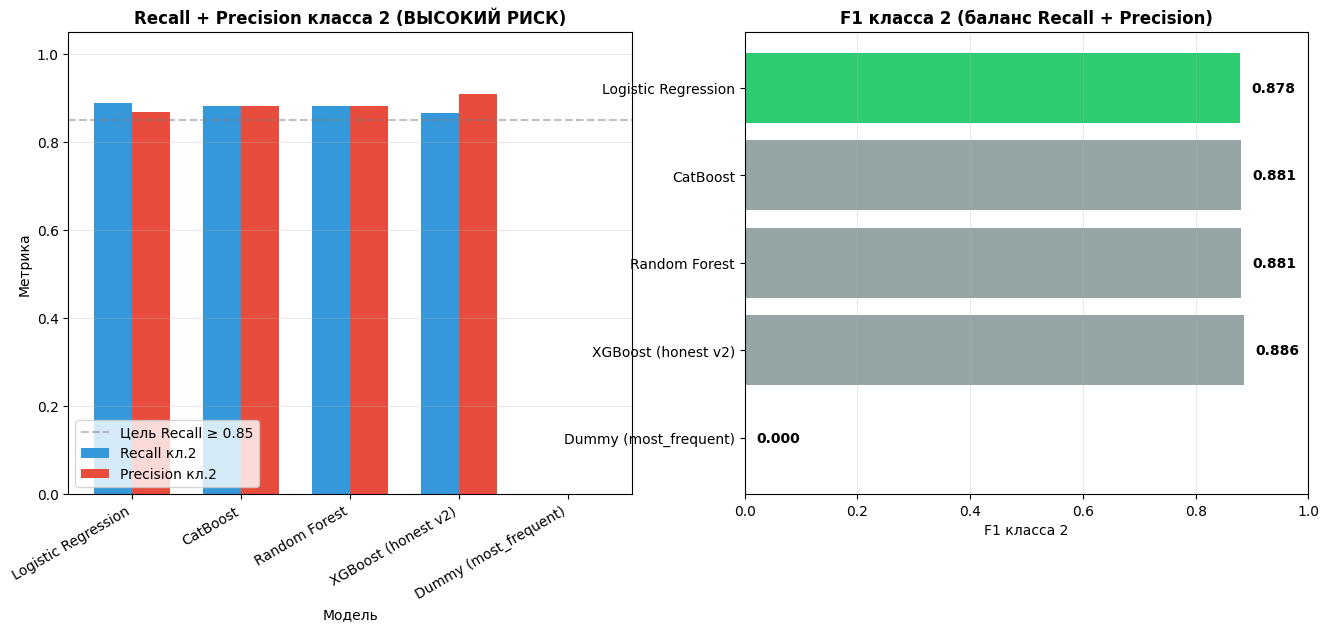

In [16]:
# ============================================================
# Визуализация сравнения моделей
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Слева: Recall + Precision по моделям ---
models_list = df_results['model'].tolist()
x = np.arange(len(models_list))
width = 0.35

axes[0].bar(x - width/2, df_results['recall_c2'], width, label='Recall кл.2', color='#3498db')
axes[0].bar(x + width/2, df_results['precision_c2'], width, label='Precision кл.2', color='#e74c3c')
axes[0].set_xlabel('Модель')
axes[0].set_ylabel('Метрика')
axes[0].set_title('Recall + Precision класса 2 (ВЫСОКИЙ РИСК)', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_list, rotation=30, ha='right')
axes[0].set_ylim(0, 1.05)
axes[0].axhline(y=0.85, color='gray', linestyle='--', alpha=0.5, label='Цель Recall ≥ 0.85')
axes[0].legend(loc='lower left')
axes[0].grid(axis='y', alpha=0.3)

# --- Справа: F1 (баланс) ---
colors_f1 = ['#2ecc71' if i == best_idx else '#95a5a6' for i in range(len(models_list))]
axes[1].barh(models_list[::-1], df_results['f1_c2'][::-1], color=colors_f1[::-1])
axes[1].set_xlabel('F1 класса 2')
axes[1].set_title('F1 класса 2 (баланс Recall + Precision)', fontweight='bold')
axes[1].set_xlim(0, 1)
for i, v in enumerate(df_results['f1_c2'][::-1]):
    axes[1].text(v + 0.02, i, f'{v:.3f}', va='center', fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

# plt.tight_layout()
# plt.savefig(f'{MODELS_DIR}/all_models_comparison.png', dpi=100, bbox_inches='tight')
# plt.show()

# print(f"✅ Сохранено: all_models_comparison.png")

# ВЫВОД

Для деплоя выбран XGBoost, так как он обеспечивает наилучший баланс (F1-мера 0.886) и максимальную точность (Precision 0.908) среди всех протестированных моделей. В отличие от Logistic Regression, которая дает много ложных тревог, и Random Forest, которая уступает по F1, XGBoost гарантирует, что 9 из 10 рекомендаций о высоком риске будут действительно критичными, а встроенный early stopping защищает модель от переобучения